# Partie B — Cavité entraînée pour plusieurs $Re < 7500$ : topologie, comparaison M1 / M2 / Ghia, $P(Re)$

Énoncé, Partie B : calculer l'écoulement pour plusieurs $Re < 7500$, décrire l'évolution de la topologie, comparer à la
littérature et à un autre solveur validé ; tracer $P(Re)$ et identifier une loi d'échelle. Plan : `PLAN.md`, étape 4.

Plan du notebook :

1. Calculs M1 (projection) et M2 ($\psi$–$\omega$) à $Re = 400, 1000, 3200, 5000$ (colonnes disponibles chez Ghia),
   $N = 128$ (grille retenue en Partie A) et $N = 64$ (contrôle) ; test du critère d'arrêt à $Re = 5000$ (ADR 0003).
2. Topologie : lignes de courant des deux méthodes, centres des tourbillons comparés à Ghia et al. (1982).
3. Comparaison des **champs** M1 / M2 : vorticité et écart de vitesse, pour chaque $Re$.
4. Profils sur les lignes médianes comparés à Ghia.
5. $K(t)$, $P(t)$ et résidu.
6. $P(Re)$ et loi d'échelle.

Mêmes réglages qu'en Partie A (validés à $Re = 100$) : grille colocalisée, Euler explicite, advection **centrée**, diffusion
centrée, gradient conjugué tol $= 10^{-8}$ départ à chaud, Neumann à fantômes pour $p$ (M1), Thom pour $\omega$ de paroi (M2),
$\Delta t$ = limites de stabilité du cours (§5.3), arrêt sur le résidu stationnaire $\|R\| < \varepsilon\|R(t_\text{ref})\|$,
$\varepsilon = 10^{-2}$, $t_\text{ref} = 10$.

In [1]:
# Imports et chemins (comme le notebook A)
import os
# Contournement d'un défaut de l'environnement CFD sur cette machine (cf. notebook A) : MKL en séquentiel,
# à fixer AVANT le premier import de numpy.
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

from cavity.common import solve_poisson, time_step
from cavity.projection import run_projection
from cavity.psi_omega import run_psi_omega

RE_LIST = (400, 1000, 3200, 5000)  # colonnes de Ghia (1982) sous Re = 7500
GRIDS = (64, 128)                  # N = 128 retenu en Partie A ; N = 64 en contrôle
N_REF = 128
CG_TOL = 1e-8                      # validé en Partie A (§2.h)
EPS = 1e-2                         # validé en Partie A (§2.b), revérifié ici à Re = 5000 (§1.b)
T_REF = 10.0
T_MAX = 1000.0                     # garde-fou : l'amortissement est lent à haut Re (ADR 0003 §2)
RECOMPUTE = False
RUNNERS = {"M1": run_projection, "M2": run_psi_omega}
STYLE = {"M1": dict(ls="-"), "M2": dict(ls="--")}
LABEL = {"M1": "M1 (projection)", "M2": r"M2 ($\psi$–$\omega$)"}


def run_path(method, re, n, eps=EPS):
    return RES / f"B_{method}_Re{re}_N{n}_tol{CG_TOL:.0e}_res{eps:.0e}.npz"


def save_run(run, path):
    np.savez(path, **{key: np.asarray(val) for key, val in run.items()})


def load_run(path):
    data = np.load(path)
    return {key: (data[key].item() if data[key].ndim == 0 else data[key]) for key in data.files}


def compute_missing(cases):
    # cases : tuples (méthode, Re, N, ε). Calculs indépendants ⇒ lancés EN PARALLÈLE, un processus par cas
    # (comme en Partie A). Résultats sauvegardés dans results/ et relus s'ils existent.
    from concurrent.futures import ProcessPoolExecutor
    missing = [c for c in cases if RECOMPUTE or not run_path(*c).exists()]
    if not missing:
        return
    os.environ["PYTHONPATH"] = str(ROOT)      # les processus fils doivent trouver le paquet cavity/
    with ProcessPoolExecutor(max_workers=len(missing)) as pool:
        futures = {c: pool.submit(RUNNERS[c[0]], c[2], c[1], "centered", cg_tol=CG_TOL, residual_tol=c[3],
                                  t_ref=T_REF, t_max=T_MAX) for c in missing}
        for case, future in futures.items():
            save_run(future.result(), run_path(*case))
            print("calculé :", case)


def get_run(method, re, n, eps=EPS):
    return load_run(run_path(method, re, n, eps))


def slope(x, y):
    # Pente des moindres carrés de y en fonction de x, écrite à la main : cov(x, y) / var(x) (cf. notebook A)
    x, y = np.asarray(x, float), np.asarray(y, float)
    dx = x - x.mean()
    return np.sum(dx * (y - y.mean())) / np.sum(dx * dx)

## 1. Calculs

### 1.a Les 16 calculs (2 méthodes × 4 $Re$ × 2 grilles)

**Ce qu'on fait.** M1 et M2 depuis le repos jusqu'au stationnaire, pour chaque $Re$ et $N = 64, 128$, en parallèle.

**Ce qu'on attend.**
- $\Delta t$ (ADR 0003 §1) : à ces $Re$, c'est la condition du schéma centré, $\Delta t \le 2\nu = 2/Re$ (marge 0.8), qui est active, sauf
  à $Re = 400$, $N = 128$ où la CFL ($h/2$) est plus petite. Elle **ne dépend pas de $N$** : $N = 64$ et $128$ ont le même $\Delta t$.
  C'est le coût du schéma centré à haut $Re$ : $\sim 10^6$ pas à $Re = 5000$.
- Le taux d'amortissement $\lambda$ de l'approche du stationnaire **diminue** quand $Re$ augmente (la viscosité amortit moins vite ;
  $\lambda \to 0$ à l'approche de $Re_c \approx 8000$) : l'arrêt est de plus en plus tardif.

In [2]:
CASES = [(m, re, n, EPS) for re in RE_LIST for n in GRIDS for m in ("M1", "M2")]
compute_missing(CASES)
runs = {(m, re, n): get_run(m, re, n) for (m, re, n, _) in CASES}


def active_limit(h, nu):
    # Quelle limite de stabilité fixe Δt (cf. cavity/common.time_step, schéma centré)
    limits = {"Fourier": h**2 / (4 * nu), "CFL": h / 2, "centré 2ν": 2 * nu}
    return min(limits, key=limits.get)


def damping_rate(r):
    # λ = -pente de ln||R|| sur la seconde moitié de [t_ref, t_final] (régime exponentiel final)
    t = r["t"]
    late = t >= T_REF + 0.5 * (r["t_final"] - T_REF)
    return -slope(t[late], np.log(r["residual"][late]))


print(f"{'méth.':>5} {'Re':>5} {'N':>4} {'dt':>9} {'limite':>9} {'pas':>8} {'t_final':>7} {'λ':>6} "
      f"{'calcul (min)':>12} {'it. GC':>6} {'arrêt':>8}")
for (m, re, n), r in runs.items():
    stop = "critère" if r["converged"] else "t_max !"
    print(f"{m:>5} {re:5d} {n:4d} {r['dt']:9.2e} {active_limit(r['h'], r['nu']):>9} {r['n_steps']:8d} "
          f"{r['t_final']:7.1f} {damping_rate(r):6.3f} {r['wall_time'] / 60:12.1f} {r['cg_iterations'].mean():6.1f} {stop:>8}")
print("Temps mesurés avec 17 calculs en parallèle sur 12 cœurs : temps pessimistes.")

méth.    Re    N        dt    limite      pas t_final      λ calcul (min) it. GC    arrêt
   M1   400   64  4.00e-03 centré 2ν     7244    29.0  0.260          1.1  141.8  critère
   M2   400   64  4.00e-03 centré 2ν     7630    30.5  0.242          0.7  130.3  critère
   M1   400  128  3.13e-03       CFL     9242    28.9  0.261          7.8  272.1  critère
   M2   400  128  3.13e-03       CFL     9461    29.6  0.253          5.3  260.2  critère
   M1  1000   64  1.60e-03 centré 2ν    22833    36.5  0.192          2.3   97.2  critère
   M2  1000   64  1.60e-03 centré 2ν    25009    40.0  0.184          2.0  123.8  critère
   M1  1000  128  1.60e-03 centré 2ν    22548    36.1  0.196         13.2  220.3  critère
   M2  1000  128  1.60e-03 centré 2ν    22967    36.7  0.198         11.7  252.3  critère
   M1  3200   64  5.00e-04 centré 2ν   207942   104.0  0.050         10.9   43.1  critère
   M2  3200   64  5.00e-04 centré 2ν   180932    90.5  0.058         11.1   98.7  critère
   M1  320

**Lecture.**
- **$\Delta t$** : la condition du schéma centré ($2\nu$) est active partout sauf à $Re = 400$, $N = 128$ (CFL) ; à $Re \ge 1000$, $N = 64$ et $128$ ont le
  même $\Delta t$. Nombre de pas : $\sim 10^4$ à $Re = 400$, $2\cdot10^5$ à $Re = 3200$, $3$ à $5\cdot10^5$ à $Re = 5000$.
- Tous les calculs s'arrêtent par le critère. **$\lambda$ diminue avec $Re$** : $\approx 0.25$ ($Re = 400$), $0.19$ ($1000$), $0.04$–$0.06$ ($3200$), $\approx 0.03$ ($5000$),
  comme attendu. Mais l'arrêt est **prématuré à $Re \ge 3200$** (§1.b).
- Temps de calcul : jusqu'à 34 min (M1, $N = 128$). Les 1077 min affichées pour M2, $Re = 5000$, $N = 128$ incluent une mise en veille de la machine
  pendant la nuit (environ 2 h de calcul effectif).
- **Deux calculs aberrants : M2, $N = 64$, $Re = 3200$ et $5000$.** Ils s'arrêtent normalement, mais sur une **solution fausse** : $K = 0.008$ et $0.006$
  au lieu de $\approx 0.04$, $\psi_\min = -0.03$ et $-0.02$ au lieu de $-0.12$ ; le tourbillon principal est remplacé par un grand tourbillon de sens inverse
  ($\psi > 0$) et un petit tourbillon horaire sous le coin haut droit ; oscillations nœud à nœud de $u$ d'amplitude $0.74$. Le Péclet de maille vaut
  $Uh/\nu = 50$ et $78$, très au-dessus de 2 : c'est le régime où le schéma centré oscille (PLAN §2, « Schéma centré à haut $Re$ »). M1 sur la même grille
  reste sur la bonne solution : la combinaison M2 + centré + Thom à grille grossière est en cause, sans qu'on ait isolé le mécanisme. C'est un exemple de
  **choix malheureux** à garder pour le rapport. Les comparaisons de topologie et de champs (§2–3) sont faites à $N = 128$.

### 1.b Le critère d'arrêt à $Re = 5000$ (ADR 0003 §2)

**Pourquoi.** L'erreur d'arrêt vaut $|u - u_\infty| \approx |\partial_t u|/\lambda$ : avec $\lambda$ petit, un même $\varepsilon$ laisse une erreur plus
grande. $\varepsilon = 10^{-2}$ a été validé à $Re = 100$ ; l'ADR demande de refaire le test au cas le plus défavorable, $Re = 5000$.

**Ce qu'on fait.** M1, $N = 64$ (le test à $N = 128$ coûterait plusieurs heures de plus) : $\varepsilon = 10^{-2}$ contre $10^{-3}$, écart des profils
comparé à l'écart à Ghia, même règle qu'en Partie A (au plus 10 %).

In [3]:
compute_missing([("M1", 5000, 64, 1e-3)])
ghia_u = np.loadtxt(ROOT / "ref_data" / "ghia1982_u_vertical_centerline.csv", delimiter=",")
ghia_v = np.loadtxt(ROOT / "ref_data" / "ghia1982_v_horizontal_centerline.csv", delimiter=",")
y_ghia = np.round(ghia_u[:, 0] * 128) / 128          # positions exactes (multiples de 1/128), cf. notebook A
x_ghia = np.round(ghia_v[:, 0] * 128) / 128
GHIA_COL = {100: 1, 400: 2, 1000: 3, 3200: 4, 5000: 5}
# Coquilles connues de l'article (ref_data/README.md) : points ignorés
BAD_U = {3200: [0.4531]}
BAD_V = {400: [0.9063]}


def ghia_profiles(re):
    # Points de Ghia intérieurs (les points de paroi sont imposés), coquilles retirées
    yu, u = y_ghia, ghia_u[:, GHIA_COL[re]]
    xv, v = x_ghia, ghia_v[:, GHIA_COL[re]]
    ok_u = (yu > 0) & (yu < 1) & ~np.isin(np.round(ghia_u[:, 0], 4), BAD_U.get(re, []))
    ok_v = (xv > 0) & (xv < 1) & ~np.isin(np.round(ghia_v[:, 0], 4), BAD_V.get(re, []))
    return yu[ok_u], u[ok_u], xv[ok_v], v[ok_v]


def centerlines(run):
    # u(0.5, y) : colonne i = N/2 ; v(x, 0.5) : ligne j = N/2
    n = run["N"]
    return run["u"][n // 2, :], run["v"][:, n // 2]


def ghia_errors(run, re):
    # Écart max à Ghia, notre profil interpolé linéairement aux points de Ghia (comme en Partie A)
    yu, ug, xv, vg = ghia_profiles(re)
    u_c, v_c = centerlines(run)
    return (np.abs(np.interp(yu, run["y"], u_c) - ug).max(), np.abs(np.interp(xv, run["x"], v_c) - vg).max())


r_a, r_b = runs[("M1", 5000, 64)], get_run("M1", 5000, 64, eps=1e-3)
ua, va = centerlines(r_a)
ub, vb = centerlines(r_b)
eu, ev = ghia_errors(r_b, 5000)
print(f"Re = 5000, M1, N = 64 : arrêt à t = {r_a['t_final']:.1f} (ε = 1e-2) et t = {r_b['t_final']:.1f} (ε = 1e-3)")
print(f"max|Δu| = {np.abs(ua - ub).max():.2e} ({np.abs(ua - ub).max() / eu:.1%} de l'écart à Ghia)   "
      f"max|Δv| = {np.abs(va - vb).max():.2e} ({np.abs(va - vb).max() / ev:.1%})")
print(f"K : {r_a['K'][-1]:.6f} / {r_b['K'][-1]:.6f}    P : {r_a['P'][-1]:.6f} / {r_b['P'][-1]:.6f}")

Re = 5000, M1, N = 64 : arrêt à t = 151.0 (ε = 1e-2) et t = 314.3 (ε = 1e-3)
max|Δu| = 2.89e-02 (56.8% de l'écart à Ghia)   max|Δv| = 2.96e-02 (20.6%)
K : 0.049297 / 0.053147    P : 0.010575 / 0.010579


**Lecture.** **Le test échoue** : passer de $\varepsilon = 10^{-2}$ à $10^{-3}$ change les profils de $0.029$, soit **57 %** de l'écart à Ghia en $u$ (21 % en $v$),
bien au-delà de la règle des 10 %. $K$ augmente encore de 8 % (0.0493 → 0.0531), alors que **$P$ ne bouge pas** (4 chiffres identiques).
- Cause : un mode très lent, $\lambda \approx \ln 10/(314 - 151) \approx 0.014$ (une décade de $\varepsilon$ coûte 160 unités de temps). Le grand tourbillon finit de
  s'accélérer très lentement, alors que la couche limite du couvercle, qui fixe $P$, s'ajuste vite. C'est le risque annoncé par l'ADR 0003 §2 ($\lambda$ petit à haut $Re$).
- Autre signe : au même $Re$, l'instant d'arrêt varie de $t = 61$ à $175$ selon la méthode et la grille. À haut $Re$, $t_\text{ref} = 10$ tombe en plein transitoire
  (bosse du résidu, §5) : la référence $\|R(t_\text{ref})\|$ du critère dépend du calcul.
- **Conséquence** : à $Re = 3200$ et $5000$, nos états « stationnaires » ne le sont pas tout à fait. $K$ est sous-estimé de quelques %, les profils sont
  incertains de $\sim 0.03$ ; **$P$ et la topologie sont fiables**. Relancer ces cas avec $\varepsilon = 10^{-3}$ : **à faire** (PLAN, étape 4).

## 2. Topologie de l'écoulement

### 2.a Lignes de courant, M1 et M2 ($N = 128$)

**Ce qu'on fait.** Iso-$\psi$ pour chaque $Re$. M2 calcule $\psi$ directement. Pour M1, on la reconstruit comme M2 le fait à chaque pas :
vorticité $\omega = \partial_x v - \partial_y u$ par différences centrées (cours §2.2) aux nœuds intérieurs, puis $\Delta\psi = -\omega$, $\psi = 0$ aux
parois, par le même gradient conjugué (cours §4.7.3). Convention : $u = \partial_y\psi$, $v = -\partial_x\psi$ ; le tourbillon principal tourne
dans le sens horaire, $\psi < 0$ ; les tourbillons secondaires tournent en sens inverse, $\psi > 0$ (tracés en rouge, niveaux logarithmiques
car ils sont 100 à $10^5$ fois plus faibles).

**Ce qu'on attend** (Ghia et al. 1982, Fig. 3 et Table V) : le centre du tourbillon principal descend vers le centre de la cavité
quand $Re$ augmente ; deux tourbillons secondaires dans les coins du bas (BL, BR) qui grossissent ; un tourbillon secondaire en haut
à gauche (TL) qui apparaît entre $Re = 1000$ et $3200$.

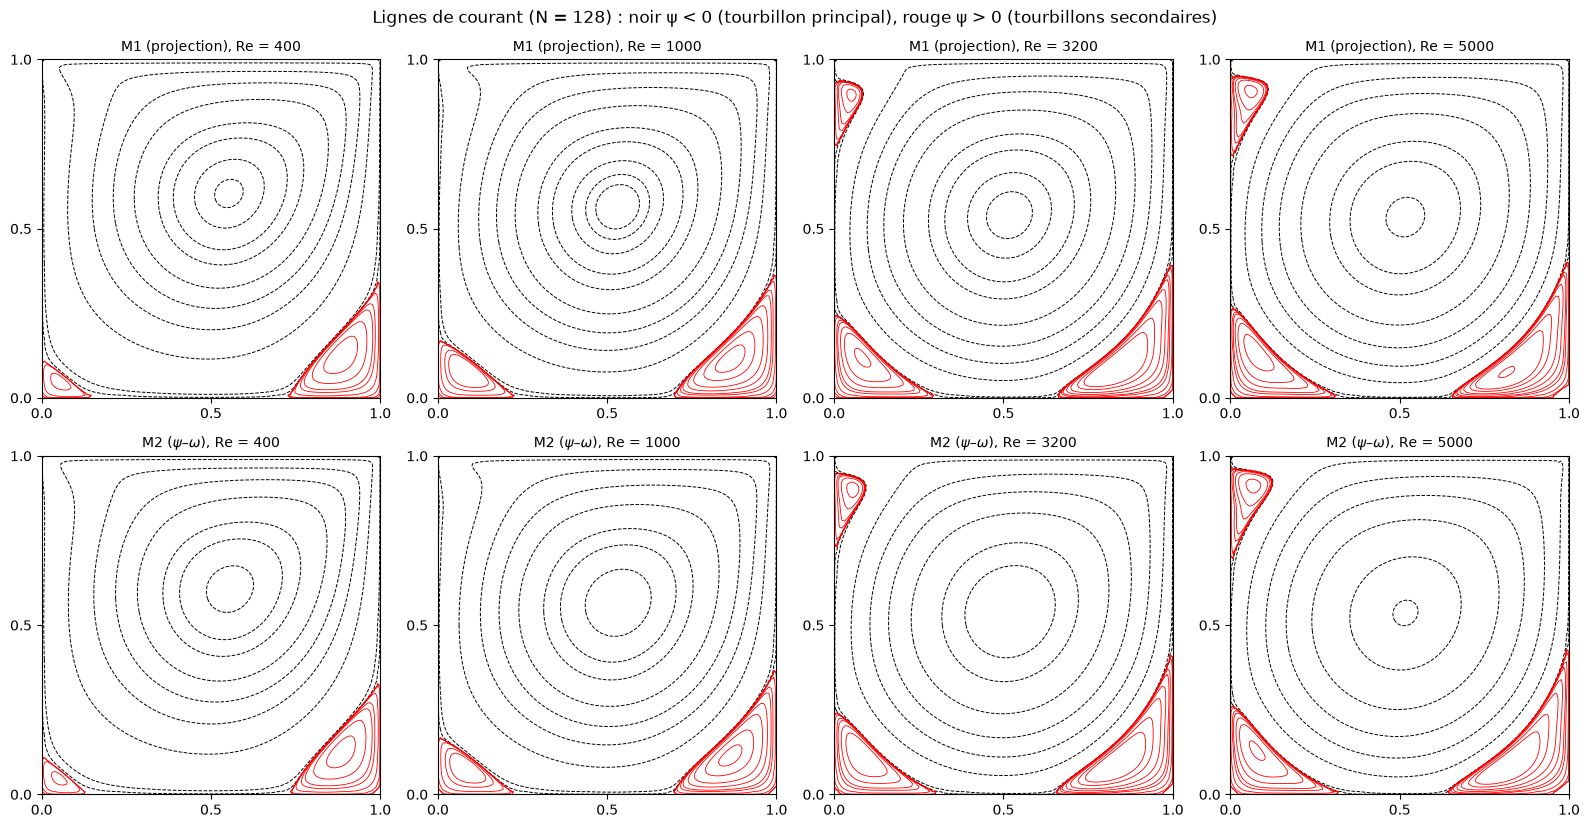

In [4]:
def streamfunction(run):
    # ψ du calcul : stockée par M2 ; reconstruite pour M1 (Δψ = -ω, ψ = 0 aux parois, gradient conjugué)
    if "psi" in run:
        return run["psi"]
    u, v, h = run["u"], run["v"], run["h"]
    omega_in = ((v[2:, 1:-1] - v[:-2, 1:-1]) - (u[1:-1, 2:] - u[1:-1, :-2])) / (2.0 * h)
    psi, _ = solve_poisson(-omega_in, h, "dirichlet", tol=1e-12)
    return psi


def vorticity(run):
    # ω aux nœuds intérieurs : variable de M2 ; pour M1, différences centrées des vitesses (cours §2.2)
    if "omega" in run:
        return run["omega"][1:-1, 1:-1]
    u, v, h = run["u"], run["v"], run["h"]
    return ((v[2:, 1:-1] - v[:-2, 1:-1]) - (u[1:-1, 2:] - u[1:-1, :-2])) / (2.0 * h)


psis = {key: streamfunction(r) for key, r in runs.items()}
LEV_NEG = np.array([-0.1175, -0.115, -0.11, -0.10, -0.09, -0.07, -0.05, -0.03, -0.01, -1e-4, -1e-5])
LEV_POS = np.array([1e-8, 1e-7, 1e-6, 1e-5, 5e-5, 1e-4, 2.5e-4, 5e-4, 1e-3, 1.5e-3, 3e-3])

fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for col, re in enumerate(RE_LIST):
    for row, m in enumerate(("M1", "M2")):
        r = runs[(m, re, N_REF)]
        ax = axes[row, col]
        X, Y = np.meshgrid(r["x"], r["y"], indexing="ij")
        ax.contour(X, Y, psis[(m, re, N_REF)], levels=LEV_NEG, colors="k", linewidths=0.7)
        ax.contour(X, Y, psis[(m, re, N_REF)], levels=LEV_POS, colors="r", linewidths=0.6)
        ax.set_aspect("equal"); ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
        ax.set_title(f"{LABEL[m]}, Re = {re}", fontsize=10)
fig.suptitle(f"Lignes de courant (N = {N_REF}) : noir ψ < 0 (tourbillon principal), rouge ψ > 0 (tourbillons secondaires)")
fig.tight_layout()
fig.savefig(FIG / "B_streamlines.png", dpi=150)
plt.show()

**Lecture.** À $N = 128$, **M1 et M2 donnent la même topologie**, et son évolution est celle décrite par Ghia :
- le tourbillon principal se recentre ($(0.55, 0.60)$ à $Re = 400$, $(0.52, 0.53)$ à $Re = 5000$) et s'arrondit ;
- les deux tourbillons secondaires du bas (BL, BR) grossissent avec $Re$ (BR occupe environ $0.25$ du côté à $Re = 400$, $0.35$ à $Re = 5000$) ;
- **un troisième tourbillon secondaire apparaît en haut à gauche (TL) entre $Re = 1000$ et $3200$**, pour les deux méthodes, comme chez Ghia.
Sur les cartes de $\omega$ (§3), le cœur du tourbillon principal devient à vorticité presque uniforme, entouré de couches de cisaillement minces le long des parois.

### 2.b Centres des tourbillons, comparés à Ghia et al. (1982), Table V

**Ce qu'on fait.** Tourbillon principal : nœud du minimum de $\psi$. Tourbillons secondaires BL, BR, TL : nœud du maximum de $\psi$
($\psi > 0$) dans le quart de cavité du coin concerné ; « absent » si $\psi$ n'y dépasse pas $10^{-7}$ (bien au-dessus de l'erreur du
gradient conjugué). Précision de position : $h = 1/128 \approx 0.008$ (la grille de Ghia pour $Re \le 3200$).

Valeurs de Ghia : lues dans la Table V de l'article (`doc_ref/`, texte extrait par OCR). On ne garde que $\psi_\min$ et la position du tourbillon principal,
et les **positions** des tourbillons secondaires ; leurs valeurs de $\psi$ sont illisibles dans l'extraction (exposants), on ne les utilise pas.
**À vérifier à l'œil sur le PDF** (pages 408–409 de l'article).

**Ce qu'on attend.** Accord de M1 et M2 entre eux et avec Ghia à quelques $h$ près ; le tourbillon principal un peu moins intense chez
M2 que chez M1 (en Partie A, M1 creusait plus les extrema de vitesse).

In [5]:
# Ghia et al. (1982), Table V (à vérifier sur le PDF) : principal = (ψ_min, x, y) ; secondaires = (x, y)
GHIA_VORTEX = {
    400:  {"principal": (-0.113909, 0.5547, 0.6055), "BL": (0.0508, 0.0469), "BR": (0.8906, 0.1250)},
    1000: {"principal": (-0.117929, 0.5313, 0.5625), "BL": (0.0859, 0.0781), "BR": (0.8594, 0.1094)},
    3200: {"principal": (-0.120377, 0.5165, 0.5469), "BL": (0.0859, 0.1094), "BR": (0.8125, 0.0859),
           "TL": (0.0547, 0.8984)},
    5000: {"principal": (-0.118966, 0.5117, 0.5352), "BL": (0.0703, 0.1367), "BR": (0.8086, 0.0742),
           "TL": (0.0625, 0.9102)},
}
CORNERS = {"BL": ("low", "low"), "BR": ("high", "low"), "TL": ("low", "high")}   # (côté en x, côté en y)


def vortex_centers(run, psi):
    # Renvoie {nom: (ψ, x, y)} ; principal = min de ψ ; coins = max de ψ > 1e-7 dans le quart de cavité
    x, y = run["x"], run["y"]
    i, j = np.unravel_index(np.argmin(psi), psi.shape)
    out = {"principal": (psi[i, j], x[i], y[j])}
    half = run["N"] // 2
    for name, (sx, sy) in CORNERS.items():
        ii = slice(0, half) if sx == "low" else slice(half, None)
        jj = slice(0, half) if sy == "low" else slice(half, None)
        sub = psi[ii, jj]
        k, l = np.unravel_index(np.argmax(sub), sub.shape)
        if sub[k, l] > 1e-7:
            out[name] = (sub[k, l], x[ii][k], y[jj][l])
    return out


centers = {key: vortex_centers(runs[key], psis[key]) for key in runs}
for re in RE_LIST:
    print(f"--- Re = {re}  (N = {N_REF})")
    for name in ("principal", "BL", "BR", "TL"):
        g = GHIA_VORTEX[re].get(name)
        txt = []
        for m in ("M1", "M2"):
            c = centers[(m, re, N_REF)].get(name)
            txt.append(f"{m}: " + ("absent" + " " * 24 if c is None else f"ψ = {c[0]: .3e} ({c[1]:.4f}, {c[2]:.4f})"))
        if g is None:
            gtxt = "Ghia : absent"
        elif name == "principal":
            gtxt = f"Ghia : ψ = {g[0]: .4f} ({g[1]:.4f}, {g[2]:.4f})"
        else:
            gtxt = f"Ghia : ({g[0]:.4f}, {g[1]:.4f})"
        print(f"  {name:>9} | {txt[0]} | {txt[1]} | {gtxt}")

--- Re = 400  (N = 128)
  principal | M1: ψ = -1.160e-01 (0.5547, 0.6016) | M2: ψ = -1.127e-01 (0.5547, 0.6094) | Ghia : ψ = -0.1139 (0.5547, 0.6055)
         BL | M1: ψ =  1.722e-05 (0.0547, 0.0469) | M2: ψ =  1.410e-05 (0.0547, 0.0469) | Ghia : (0.0508, 0.0469)
         BR | M1: ψ =  7.050e-04 (0.8828, 0.1250) | M2: ψ =  6.411e-04 (0.8828, 0.1250) | Ghia : (0.8906, 0.1250)
         TL | M1: absent                         | M2: absent                         | Ghia : absent
--- Re = 1000  (N = 128)
  principal | M1: ψ = -1.197e-01 (0.5312, 0.5625) | M2: ψ = -1.148e-01 (0.5312, 0.5703) | Ghia : ψ = -0.1179 (0.5313, 0.5625)
         BL | M1: ψ =  2.414e-04 (0.0859, 0.0781) | M2: ψ =  2.053e-04 (0.0781, 0.0781) | Ghia : (0.0859, 0.0781)
         BR | M1: ψ =  1.796e-03 (0.8594, 0.1094) | M2: ψ =  1.672e-03 (0.8672, 0.1172) | Ghia : (0.8594, 0.1094)
         TL | M1: absent                         | M2: absent                         | Ghia : absent
--- Re = 3200  (N = 128)
  principal | 

**Lecture.**
- **Positions** : tous les centres (principal, BL, BR, TL) sont à 1 ou 2 mailles de ceux de Ghia, pour les deux méthodes (écart max $0.016$, BR à $Re = 3200$).
- **Intensité du tourbillon principal** : à $Re \le 1000$, $\psi_\min$ est à 2–3 % de Ghia pour M1 ($-0.116$, $-0.120$) comme pour M2 ($-0.113$, $-0.115$). À $Re = 3200$ et
  $5000$, les deux sont **plus faibles** que Ghia ($-0.120$, $-0.119$) : M1 de 3 et 6 % ($-0.117$, $-0.111$), M2 de 11 et 15 % ($-0.108$, $-0.101$). Deux raisons
  connues : le tourbillon s'accélère encore quand le calcul s'arrête (§1.b), et à $Re = 5000$ Ghia est deux fois plus fin que nous.
- $|\psi_\min|$ est toujours plus grand pour M1 que pour M2, comme les extrema de vitesse en Partie A.

## 3. Comparaison des champs M1 / M2

**Ce qu'on fait.** Pour chaque $Re$, à $N = 128$ : la vorticité des deux méthodes (M2 : sa variable $\omega$ ; M1 : différences centrées
des vitesses, nœuds intérieurs), et la carte de l'écart de vitesse $\|\mathbf u_{M1} - \mathbf u_{M2}\| = \sqrt{(u_1-u_2)^2 + (v_1-v_2)^2}$.
L'échelle de couleur de $\omega$ est bornée à $\pm 5$ (comme les iso-$\omega$ de Ghia, Table III) : aux coins du couvercle, $\omega \sim 1/h$ (singularité).
L'écart de vitesse est en échelle **logarithmique** : il est maximal aux deux coins du couvercle (saut de vitesse), ce qui écraserait une échelle
linéaire ; on donne aussi son maximum hors de ces coins (à plus de $0.05$ de chacun) et sa moyenne quadratique.

**Ce qu'on attend.** Les mêmes structures pour les deux méthodes. L'écart (erreur de projection de M1 qui dépend de $\Delta t$, Partie A
§2.e ; erreur d'espace des deux méthodes) devrait se concentrer là où les gradients sont forts : couche limite du couvercle, couches
de cisaillement qui se détachent des parois. Il devrait **croître avec $Re$** à $N$ fixé (couches plus minces, moins bien résolues).

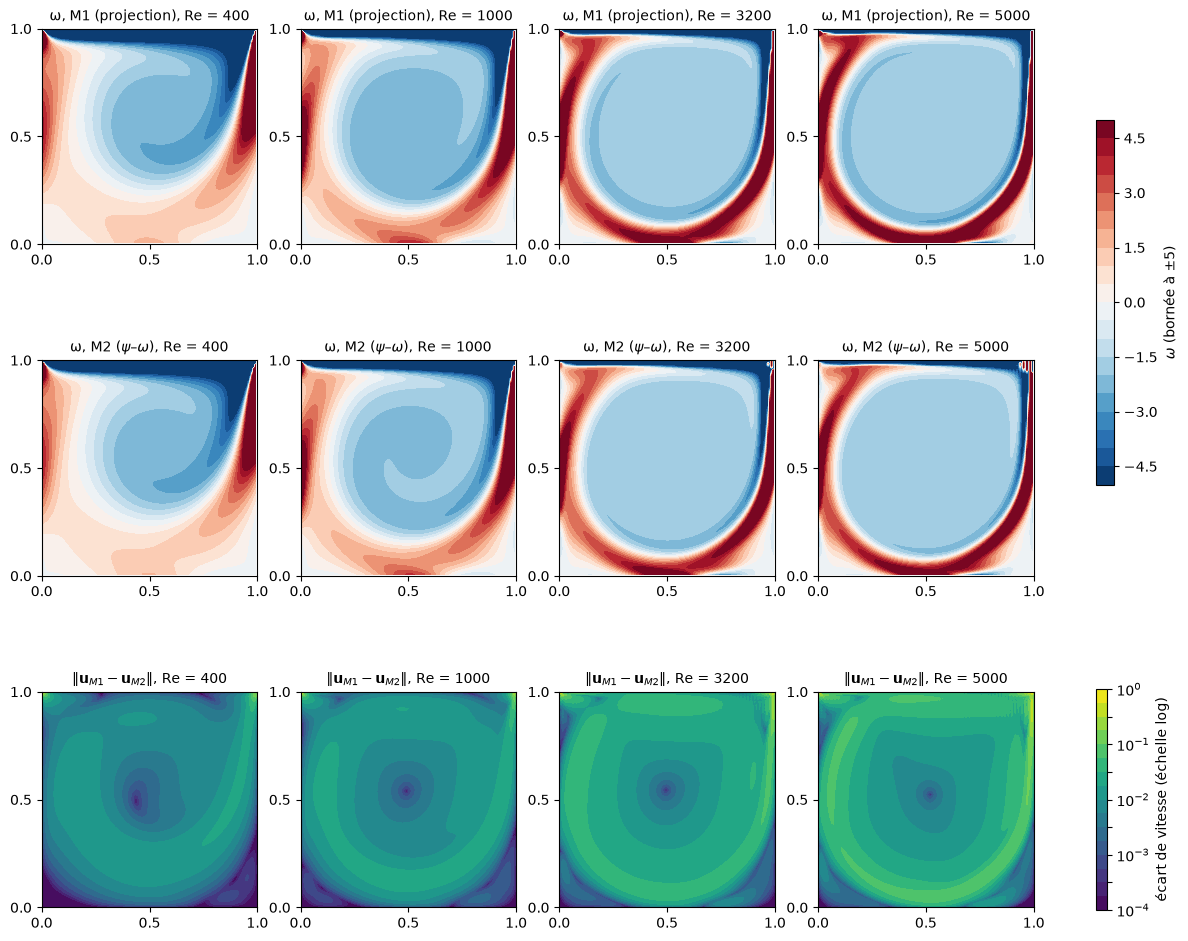

Écart de vitesse ||u_M1 - u_M2|| sur le champ (N = 128) et écart max M1 - M2 sur les lignes médianes :
   Re =   400   champ : max 0.227 (coins), max hors coins 0.0477, rms 0.0101   |   lignes médianes : N = 64 0.0388, N = 128 0.0189  (rapport 2.06)
   Re =  1000   champ : max 0.350 (coins), max hors coins 0.0865, rms 0.0136   |   lignes médianes : N = 64 0.0739, N = 128 0.0271  (rapport 2.73)
   Re =  3200   champ : max 0.557 (coins), max hors coins 0.2623, rms 0.0271   |   lignes médianes : N = 64 0.6397, N = 128 0.0608  (rapport 10.53)
   Re =  5000   champ : max 0.654 (coins), max hors coins 0.4058, rms 0.0367   |   lignes médianes : N = 64 0.6413, N = 128 0.1006  (rapport 6.38)


In [6]:
from matplotlib.colors import LogNorm

R_CORNER = 0.05      # rayon autour des coins du couvercle exclu pour l'écart « hors coins »
fig, axes = plt.subplots(3, 4, figsize=(16, 12.2))
diff_stats = {}
for col, re in enumerate(RE_LIST):
    r1, r2 = runs[("M1", re, N_REF)], runs[("M2", re, N_REF)]
    X, Y = np.meshgrid(r1["x"][1:-1], r1["y"][1:-1], indexing="ij")
    for row, (m, r) in enumerate((("M1", r1), ("M2", r2))):
        cs = axes[row, col].contourf(X, Y, np.clip(vorticity(r), -5, 5), levels=np.linspace(-5, 5, 21), cmap="RdBu_r")
        axes[row, col].set_title(f"ω, {LABEL[m]}, Re = {re}", fontsize=10)
    # Écart de vitesse ; échelle log : le pic des coins du couvercle (singularité) écraserait sinon tout le reste
    du = np.sqrt((r1["u"] - r2["u"])**2 + (r1["v"] - r2["v"])**2)
    Xf, Yf = np.meshgrid(r1["x"], r1["y"], indexing="ij")
    far = (np.hypot(Xf, Yf - 1) > R_CORNER) & (np.hypot(Xf - 1, Yf - 1) > R_CORNER)
    diff_stats[re] = (du.max(), du[far].max(), np.sqrt(np.mean(du**2)))
    cd = axes[2, col].contourf(Xf, Yf, np.clip(du, 1e-4, 1), levels=np.logspace(-4, 0, 17), norm=LogNorm(), cmap="viridis")
    axes[2, col].set_title(rf"$\|\mathbf{{u}}_{{M1}} - \mathbf{{u}}_{{M2}}\|$, Re = {re}", fontsize=10)
for ax in axes.ravel():
    ax.set_aspect("equal"); ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
fig.colorbar(cs, ax=axes[:2, :].ravel().tolist(), shrink=0.6, label=r"$\omega$ (bornée à $\pm 5$)")
fig.colorbar(cd, ax=axes[2, :].ravel().tolist(), shrink=0.8, label="écart de vitesse (échelle log)")
fig.savefig(FIG / "B_fields_M1_M2.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Écart de vitesse ||u_M1 - u_M2|| sur le champ (N = {N_REF}) et écart max M1 - M2 sur les lignes médianes :")
for re in RE_LIST:
    gaps = []
    for n in GRIDS:
        a1, b1 = centerlines(runs[("M1", re, n)])
        a2, b2 = centerlines(runs[("M2", re, n)])
        gaps.append(max(np.abs(a1 - a2).max(), np.abs(b1 - b2).max()))
    mx, mx_far, rms = diff_stats[re]
    print(f"   Re = {re:5d}   champ : max {mx:.3f} (coins), max hors coins {mx_far:.4f}, rms {rms:.4f}   |   "
          f"lignes médianes : N = 64 {gaps[0]:.4f}, N = 128 {gaps[-1]:.4f}  (rapport {gaps[0] / gaps[-1]:.2f})")

**Lecture.**
- **Mêmes structures** pour M1 et M2 sur les cartes de $\omega$.
- **L'écart de vitesse croît avec $Re$**, comme attendu : hors des coins, max $0.05 \to 0.09 \to 0.26 \to 0.41$ et moyenne quadratique $0.010 \to 0.037$. Il se
  concentre dans les couches de cisaillement le long des parois (anneau) et sous le couvercle ; il est faible au centre du tourbillon. Le pic aux deux coins
  du couvercle ($0.23$ à $0.65$) vient de la singularité.
- **M2 oscille près du coin haut droit à $Re = 3200$ et $5000$** (petites taches sur $\omega$, coude de $u$ vers $y = 0.97$ au §4) : oscillations nœud à nœud du schéma
  centré à Péclet de maille 25–39 ; M1 en montre beaucoup moins. Cela peut expliquer le $\psi_\min$ plus faible de M2.
- Sur les lignes médianes, l'écart M1 – M2 est divisé par $2.1$ ($Re = 400$) et $2.7$ ($Re = 1000$) de $N = 64$ à $128$ : les deux méthodes convergent vers la
  même solution. À $Re \ge 3200$, le rapport n'a pas de sens (M2 à $N = 64$ est sur la solution fausse du §1.a).

## 4. Profils sur les lignes médianes, comparés à Ghia

**Ce qu'on fait.** $u(0.5, y)$ et $v(x, 0.5)$ à $N = 128$ pour M1 et M2, avec les points de Ghia (colonne du $Re$ ; coquilles connues retirées,
`ref_data/README.md`). Écart max à Ghia pour les deux grilles, et écart entre nos grilles $N = 64$ et $128$ (indépendant de toute référence).

**Ce qu'on attend.** Accord visuel ; des écarts qui croissent avec $Re$ (couches limites plus minces pour la même grille). À $Re = 5000$,
Ghia est sur 257×257, **deux fois plus fin** que nous : un écart plus grand y est attendu (PLAN, étape 4).

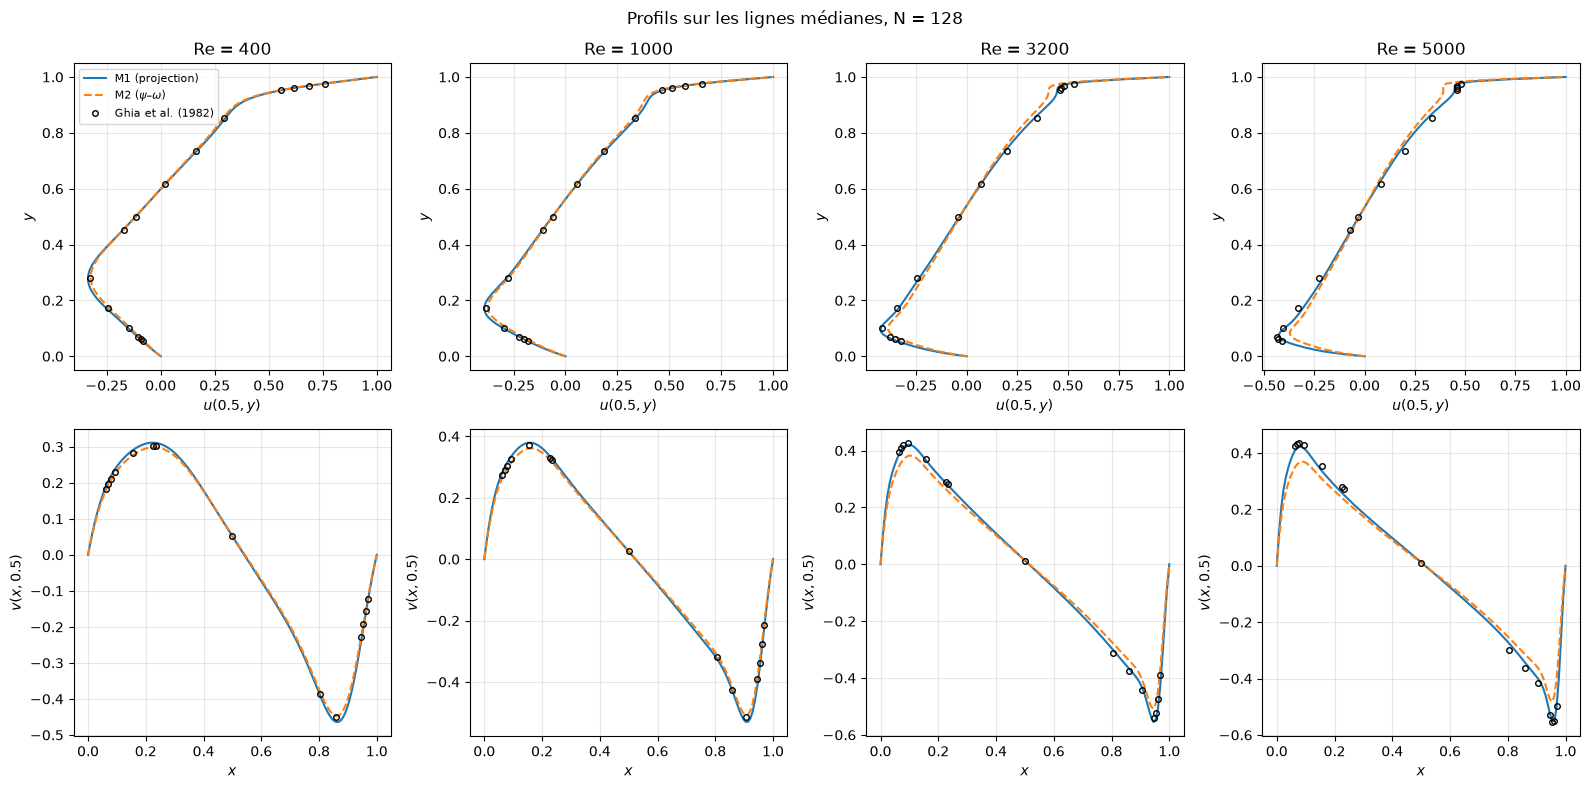

   Re méth. |   écart Ghia N=64 (u, v) |  écart Ghia N=128 (u, v) |   max|·_64 - ·_128| (u, v)
  400    M1 |      0.0070      0.0117  |      0.0090      0.0140  |       0.0075       0.0030
  400    M2 |      0.0249      0.0218  |      0.0064      0.0039  |       0.0193       0.0224
 1000    M1 |      0.0169      0.0115  |      0.0082      0.0222  |       0.0196       0.0166
 1000    M2 |      0.0649      0.0645  |      0.0162      0.0110  |       0.0511       0.0608
 3200    M1 |      0.0390      0.1447  |      0.0241      0.0369  |       0.0296       0.1416
 3200    M2 |      0.5948      0.5593  |      0.0630      0.0541  |       0.6019       0.5221
 5000    M1 |      0.0430      0.1370  |      0.0241      0.0247  |       0.0722       0.2597
 5000    M2 |      0.5831      0.5632  |      0.0835      0.0942  |       0.5375       0.4917


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, re in enumerate(RE_LIST):
    yu, ug, xv, vg = ghia_profiles(re)
    for m in ("M1", "M2"):
        r = runs[(m, re, N_REF)]
        u_c, v_c = centerlines(r)
        axes[0, col].plot(u_c, r["y"], **STYLE[m], label=LABEL[m])
        axes[1, col].plot(r["x"], v_c, **STYLE[m], label=LABEL[m])
    axes[0, col].plot(ug, yu, "ko", mfc="none", ms=4, label="Ghia et al. (1982)")
    axes[1, col].plot(xv, vg, "ko", mfc="none", ms=4, label="Ghia et al. (1982)")
    axes[0, col].set_xlabel("$u(0.5, y)$"); axes[0, col].set_ylabel("$y$")
    axes[1, col].set_xlabel("$x$"); axes[1, col].set_ylabel("$v(x, 0.5)$")
    axes[0, col].set_title(f"Re = {re}")
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Profils sur les lignes médianes, N = {N_REF}")
fig.tight_layout()
fig.savefig(FIG / "B_profiles_Ghia.png", dpi=150)
plt.show()

print(f"{'Re':>5} {'méth.':>5} | {'écart Ghia N=64 (u, v)':>24} | {'écart Ghia N=128 (u, v)':>24} | {'max|·_64 - ·_128| (u, v)':>26}")
for re in RE_LIST:
    for m in ("M1", "M2"):
        e64 = ghia_errors(runs[(m, re, 64)], re)
        e128 = ghia_errors(runs[(m, re, 128)], re)
        uc, vc = centerlines(runs[(m, re, 64)])
        uf, vf = centerlines(runs[(m, re, 128)])
        g = (np.abs(uc - uf[::2]).max(), np.abs(vc - vf[::2]).max())
        print(f"{re:5d} {m:>5} | {e64[0]:11.4f} {e64[1]:11.4f}  | {e128[0]:11.4f} {e128[1]:11.4f}  | {g[0]:12.4f} {g[1]:12.4f}")

**Lecture.**
- **$Re \le 1000$** : les deux méthodes sont sur les points de Ghia (écart $\le 0.022$ à $N = 128$).
- **$Re = 3200$ et $5000$** : M1 reste proche de Ghia ($0.024$–$0.037$) ; M2 s'en écarte ($0.054$–$0.094$) : pic de $v$ près de la paroi gauche sous-estimé
  ($0.37$ contre $0.43$ à $Re = 5000$) et coude de $u$ sous le couvercle (oscillations, §3). C'est l'inverse de la Partie A, où M2 était plus juste. Prudence
  (Partie A §3.c) : être proche de Ghia ne suffit pas à dire qu'un calcul est juste, et les deux calculs sont arrêtés trop tôt (§1.b).
- **Écart entre $N = 64$ et $128$** : il croît avec $Re$, jusqu'à $0.07$–$0.26$ pour M1 à $Re = 5000$. **$N = 128$ n'est donc pas convergé en maillage à $Re \ge 3200$**
  (Ghia passe lui-même à 257×257 à $Re = 5000$). C'est le minimum utilisable ; $N = 64$ ne l'est pas.

## 5. $K(t)$, $P(t)$ et résidu

**Ce qu'on fait.** Les deux diagnostics de l'énoncé et le résidu stationnaire, pour chaque $Re$, M1 et M2, $N = 128$.

**Ce qu'on attend.** Une montée avec la rampe du couvercle puis un palier, atteint de plus en plus tard quand $Re$ augmente ; à haut $Re$,
le transitoire peut osciller (le tourbillon principal met plusieurs tours à s'installer). $P$ stationnaire **diminue** avec $Re$ (§6).
Résidu : décroissance exponentielle finale, de plus en plus lente ($\lambda$ diminue avec $Re$).

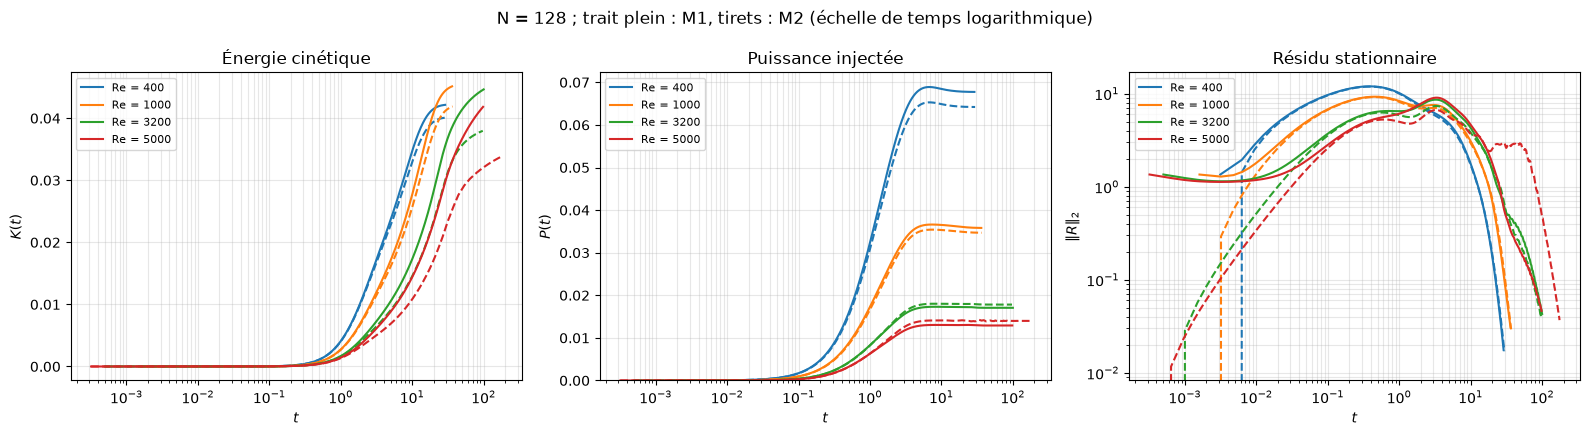

Re =   400   K : M1 0.04215, M2 0.04010   P : M1 0.06774, M2 0.06420   λ : M1 0.2615, M2 0.2529
Re =  1000   K : M1 0.04513, M2 0.04188   P : M1 0.03582, M2 0.03468   λ : M1 0.1962, M2 0.1980
Re =  3200   K : M1 0.04464, M2 0.03797   P : M1 0.01706, M2 0.01782   λ : M1 0.0409, M2 0.0388
Re =  5000   K : M1 0.04183, M2 0.03378   P : M1 0.01292, M2 0.01399   λ : M1 0.0306, M2 0.0347


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for k, re in enumerate(RE_LIST):
    for m in ("M1", "M2"):
        r = runs[(m, re, N_REF)]
        lab = f"Re = {re}" if m == "M1" else None
        axes[0].plot(r["t"], r["K"], color=f"C{k}", **STYLE[m], label=lab)
        axes[1].plot(r["t"], r["P"], color=f"C{k}", **STYLE[m], label=lab)
        axes[2].semilogy(r["t"], r["residual"], color=f"C{k}", **STYLE[m], label=lab)
axes[0].set_ylabel("$K(t)$"); axes[1].set_ylabel("$P(t)$"); axes[2].set_ylabel(r"$\|R\|_2$")
axes[1].set_ylim(0, None)
axes[0].set_title("Énergie cinétique"); axes[1].set_title("Puissance injectée"); axes[2].set_title("Résidu stationnaire")
for ax in axes:
    ax.set_xlabel("$t$"); ax.set_xscale("log"); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"N = {N_REF} ; trait plein : M1, tirets : M2 (échelle de temps logarithmique)")
fig.tight_layout()
fig.savefig(FIG / "B_K_P_residual.png", dpi=150)
plt.show()

for re in RE_LIST:
    r1, r2 = runs[("M1", re, N_REF)], runs[("M2", re, N_REF)]
    print(f"Re = {re:5d}   K : M1 {r1['K'][-1]:.5f}, M2 {r2['K'][-1]:.5f}   P : M1 {r1['P'][-1]:.5f}, M2 {r2['P'][-1]:.5f}"
          f"   λ : M1 {damping_rate(r1):.4f}, M2 {damping_rate(r2):.4f}")

**Lecture.**
- **$P$ atteint son palier vite** ($t \approx 5$–$10$, quel que soit $Re$) : il dépend de la couche limite du couvercle, qui s'établit sur le temps de la rampe.
- **$K$ met beaucoup plus de temps**, et à $Re \ge 3200$ il **monte encore** quand le calcul s'arrête (§1.b) : le grand tourbillon s'accélère lentement.
- **Résidu** : bosse vers $t \approx 3$, puis décroissance, de plus en plus lente et irrégulière quand $Re$ augmente (M2, $Re = 5000$ : palier de $t \approx 20$ à $60$
  avant de redescendre).
- $K$ est toujours plus grand pour M1 que pour M2, et l'écart grandit avec $Re$ (0.042 contre 0.040 à $Re = 400$ ; 0.042 contre 0.034 à $Re = 5000$),
  comme $\psi_\min$. Les $P$ des deux méthodes diffèrent de 8 % au plus.

## 6. $P(Re)$ et loi d'échelle

**Ce qu'on fait.** $P$ stationnaire en fonction de $Re$, en log-log, pour M1 et M2, à $N = 64$ et $128$ ; on y ajoute $Re = 100$
(Partie A, mêmes réglages). Régression linéaire de $\ln P$ en $\ln Re$ (écrite à la main) : $P \propto Re^{b}$.

**Ce qu'on attend** (PLAN §2) : couche limite sous le couvercle d'épaisseur $\delta \sim Re^{-1/2}$ (workshop 12.3), d'où
$\partial_y u \sim 1/\delta$ et $P \sim \nu/\delta \sim Re^{-1/2}$. Mais la singularité des coins ajoute un terme $\propto \nu\ln N = Re^{-1}\ln N$ (Partie A
§2.g) : la pente mesurée sera **plus forte** que $-1/2$, d'autant plus aux $Re$ modérés et à $N$ grand. Pour séparer les deux, on écrit
$P = a\,Re^{-1/2} + c\,Re^{-1}$, soit $P\sqrt{Re} = a + c\,Re^{-1/2}$ : une **droite** en $Re^{-1/2}$, dont l'ordonnée à l'origine $a$ est le coefficient
de la loi $Re^{-1/2}$ et la pente $c$ celui du terme de coin. Test : en Partie A, le terme de coin valait $\approx 4.2\,\nu\ln N$ ; $c$ doit donc
augmenter d'environ $4.2\ln 2 \approx 2.9$ de $N = 64$ à $N = 128$, et $a$ (couche limite, régulière) ne doit presque pas bouger.

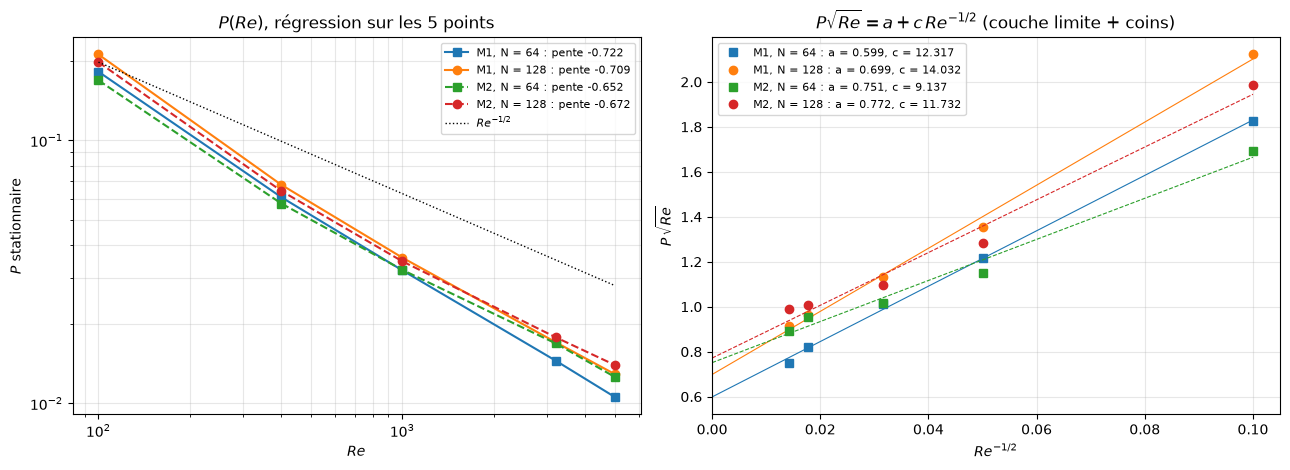

Pentes locales d ln P / d ln Re entre Re successifs :
   M1, N =  64 : P = [0.18247 0.06077 0.03205 0.01452 0.01057]   pentes locales [-0.793 -0.698 -0.681 -0.71 ]   globale -0.722   (Re ≥ 1000 : -0.687)
   M1, N = 128 : P = [0.2122  0.06774 0.03582 0.01706 0.01292]   pentes locales [-0.824 -0.696 -0.637 -0.624]   globale -0.709   (Re ≥ 1000 : -0.634)
   M2, N =  64 : P = [0.1692  0.05752 0.03218 0.01689 0.01261]   pentes locales [-0.778 -0.634 -0.554 -0.655]   globale -0.652   (Re ≥ 1000 : -0.577)
   M2, N = 128 : P = [0.1984  0.0642  0.03468 0.01782 0.01399]   pentes locales [-0.814 -0.672 -0.572 -0.541]   globale -0.672   (Re ≥ 1000 : -0.566)
Ajustement P √Re = a + c Re^(-1/2) :
   M1, N =  64 : a = 0.5987   c = 12.3168
   M1, N = 128 : a = 0.6986   c = 14.0319
   M2, N =  64 : a = 0.7512   c = 9.1373
   M2, N = 128 : a = 0.7716   c = 11.7322


In [9]:
RE_ALL = (100,) + RE_LIST


def p_final(m, re, n):
    # Re = 100 : calculs de la Partie A (mêmes réglages, ε = 1e-2, tol 1e-8, Δt de stabilité)
    if re == 100:
        return load_run(RES / f"A_{m}_N{n}_tol{CG_TOL:.0e}_res{EPS:.0e}.npz")["P"][-1]
    return runs[(m, re, n)]["P"][-1]


P = {(m, n): np.array([p_final(m, re, n) for re in RE_ALL]) for m in ("M1", "M2") for n in GRIDS}
lre = np.log(np.array(RE_ALL, float))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for k, (m, n) in enumerate(P):
    b = slope(lre, np.log(P[(m, n)]))
    ax.loglog(RE_ALL, P[(m, n)], "o" if n == 128 else "s", color=f"C{k}", **STYLE[m],
              label=f"{m}, N = {n} : pente {b:.3f}")
ref = P[("M2", N_REF)]
ax.loglog(RE_ALL, ref[0] * (np.array(RE_ALL) / 100.0)**-0.5, "k:", lw=1, label=r"$Re^{-1/2}$")
ax.set_xlabel("$Re$"); ax.set_ylabel("$P$ stationnaire"); ax.set_title("$P(Re)$, régression sur les 5 points")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
s = np.array(RE_ALL, float)**-0.5
fits = {}
for k, (m, n) in enumerate(P):
    yv = P[(m, n)] * np.sqrt(RE_ALL)
    c = slope(s, yv)
    a = yv.mean() - c * s.mean()
    fits[(m, n)] = (a, c)
    ax.plot(s, yv, "o" if n == 128 else "s", color=f"C{k}", label=f"{m}, N = {n} : a = {a:.3f}, c = {c:.3f}")
    ax.plot([0, s.max()], [a, a + c * s.max()], color=f"C{k}", lw=0.8, **STYLE[m])
ax.set_xlim(0, None)
ax.set_xlabel(r"$Re^{-1/2}$"); ax.set_ylabel(r"$P\,\sqrt{Re}$")
ax.set_title(r"$P\sqrt{Re} = a + c\,Re^{-1/2}$ (couche limite + coins)")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "B_P_Re.png", dpi=150)
plt.show()

print("Pentes locales d ln P / d ln Re entre Re successifs :")
for (m, n), p in P.items():
    loc = np.diff(np.log(p)) / np.diff(lre)
    print(f"   {m}, N = {n:3d} : P = {np.round(p, 5)}   pentes locales {np.round(loc, 3)}   "
          f"globale {slope(lre, np.log(p)):.3f}   (Re ≥ 1000 : {slope(lre[2:], np.log(p[2:])):.3f})")
print("Ajustement P √Re = a + c Re^(-1/2) :")
for (m, n), (a, c) in fits.items():
    print(f"   {m}, N = {n:3d} : a = {a:.4f}   c = {c:.4f}")

**Lecture.**
- **Pente globale** de $-0.65$ à $-0.72$, plus forte que $-1/2$, comme prévu (terme de coin $\propto Re^{-1}$).
- **Les pentes locales tendent vers $-1/2$ quand $Re$ augmente** : M2, $N = 128$ : $-0.81$, $-0.67$, $-0.57$, $-0.54$ ; M1, $N = 128$ : $-0.82$, $-0.70$, $-0.64$, $-0.62$.
  **Loi d'échelle : $P \propto Re^{-1/2}$ aux grands $Re$** (couche limite du couvercle, $\delta \sim Re^{-1/2}$), avec une correction en $Re^{-1}$ qui domine aux $Re$ modérés.
- **Modèle à deux termes** $P\sqrt{Re} = a + c\,Re^{-1/2}$ : $a \approx 0.70$–$0.77$ à $N = 128$. $c$ croît avec $N$ ($+1.7$ pour M1, $+2.6$ pour M2, contre $+2.9$ prévu
  depuis la Partie A) : c'est bien l'ordre de grandeur d'un terme de coin en $\nu\ln N$. $a$ ne bouge presque pas pour M2 ($0.75 \to 0.77$), plus pour M1
  ($0.60 \to 0.70$). Le modèle reste approché : les points ne sont pas exactement alignés (M2, $N = 128$ : $P\sqrt{Re}$ se stabilise vers $1.0$ à $Re \ge 3200$).
- **Robustesse** : les pentes à $N = 64$ et $128$ diffèrent de $0.01$–$0.02$ seulement, et $P$ ne dépend pas du critère d'arrêt (§1.b) : **ce résultat ne dépend
  pas du point « à faire »**. Réserve : les $P$ de M2, $N = 64$, à $Re \ge 3200$ viennent des solutions fausses du §1.a (ils restent proches des autres, car $P$
  ne dépend que de la couche limite du couvercle).

## 7. Récapitulatif (sauvegardé dans `results/B_summary.csv`)

In [10]:
rows = []
for (m, re, n), r in runs.items():
    eu, ev = ghia_errors(r, re)
    rows.append([re, int(m[1]), n, r["dt"], r["n_steps"], r["t_final"], r["wall_time"], r["cg_iterations"].mean(),
                 damping_rate(r), eu, ev, r["K"][-1], r["P"][-1], centers[(m, re, n)]["principal"][0]])
rows.sort()
np.savetxt(RES / "B_summary.csv", np.array(rows), delimiter=",", fmt="%.6e",
           header=f"Partie B, schema centre, critere residu eps = {EPS:.0e} (t_ref = {T_REF}), tol GC {CG_TOL:.0e}\n"
                  "Re,methode(1=M1 projection, 2=M2 psi-omega),N,dt,n_steps,t_final,wall_time_s,cg_iter_mean,lambda,"
                  "err_ghia_u,err_ghia_v,K_final,P_final,psi_min")
for row in rows:
    print(f"Re = {int(row[0]):5d}  M{int(row[1])}  N = {int(row[2]):3d}   t_final = {row[5]:6.1f}   calcul = {row[6] / 60:6.1f} min"
          f"   écart Ghia (u, v) = ({row[9]:.4f}, {row[10]:.4f})   K = {row[11]:.5f}   P = {row[12]:.5f}   ψ_min = {row[13]:.5f}")

Re =   400  M1  N =  64   t_final =   29.0   calcul =    1.1 min   écart Ghia (u, v) = (0.0070, 0.0117)   K = 0.04209   P = 0.06077   ψ_min = -0.11535
Re =   400  M1  N = 128   t_final =   28.9   calcul =    7.8 min   écart Ghia (u, v) = (0.0090, 0.0140)   K = 0.04215   P = 0.06774   ψ_min = -0.11602
Re =   400  M2  N =  64   t_final =   30.5   calcul =    0.7 min   écart Ghia (u, v) = (0.0249, 0.0218)   K = 0.03814   P = 0.05752   ψ_min = -0.10899
Re =   400  M2  N = 128   t_final =   29.6   calcul =    5.3 min   écart Ghia (u, v) = (0.0064, 0.0039)   K = 0.04010   P = 0.06420   ψ_min = -0.11269
Re =  1000  M1  N =  64   t_final =   36.5   calcul =    2.3 min   écart Ghia (u, v) = (0.0169, 0.0115)   K = 0.04338   P = 0.03205   ψ_min = -0.11623
Re =  1000  M1  N = 128   t_final =   36.1   calcul =   13.2 min   écart Ghia (u, v) = (0.0082, 0.0222)   K = 0.04513   P = 0.03582   ψ_min = -0.11969
Re =  1000  M2  N =  64   t_final =   40.0   calcul =    2.0 min   écart Ghia (u, v) = (0.0649

**Bilan de la Partie B.**
- **Topologie** ($N = 128$) : M1 et M2 concordent entre elles et avec Ghia. Le tourbillon principal se recentre, BL et BR grossissent, TL apparaît entre
  $Re = 1000$ et $3200$. Les centres sont à 1–2 mailles de ceux de Ghia.
- **$P(Re)$** : la pente locale tend vers $-1/2$ (couche limite du couvercle), avec une correction en $Re^{-1}$ (coins) qui rend la pente globale plus forte
  ($\approx -0.7$). Le résultat est robuste au maillage et au critère d'arrêt.
- **Limites, à dire à l'oral** :
  1. le critère $\varepsilon = 10^{-2}$ arrête trop tôt à $Re \ge 3200$ ($K$ et profils pas tout à fait stationnaires) : relance avec $\varepsilon = 10^{-3}$ **à faire** ;
  2. $N = 128$ n'est pas convergé en maillage à $Re \ge 3200$ ;
  3. M2 + schéma centré donne une solution fausse à $N = 64$, $Re \ge 3200$ (Péclet de maille 50–78) et oscille près du coin haut droit à $N = 128$ :
     exemple de choix malheureux. À haut $Re$, M1 est le plus fiable des deux.
- **Pour la Partie C** : à $Re = 5000$, $\lambda \approx 0.014$–$0.03$ ; le coût du schéma centré ($\Delta t \le 2\nu$) et ces oscillations sont les deux points à régler avant
  d'aller au-delà de $Re_c$.